Test the slab model with 2 islands. Fig.15 (e):
$$
\begin{align*}
&m_1=m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.5\\
&\iota'=4
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

#### Create the magnetic field:

In [2]:
field = SlabBfieldTwoPert(
    m1=1,
    n1=1,
    delta1=0.5,
    m2=1,
    n2=-1,
    delta2=0.5,
    iota_prime=4.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.25 0.75


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

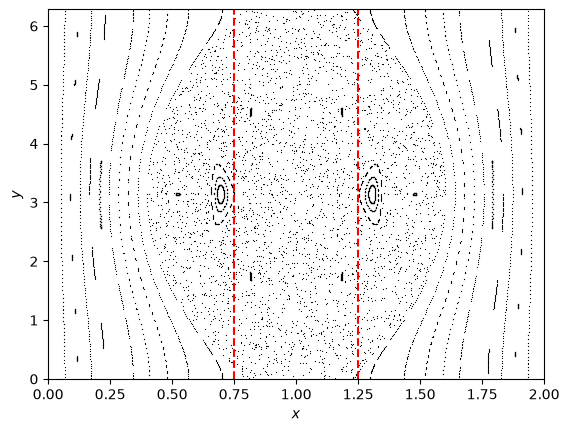

In [4]:
pplot = PoincarePlot.with_linspace(
    map,
    np.array([0.05, np.pi]),
    np.array([1.95, np.pi]),
    npts=50
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

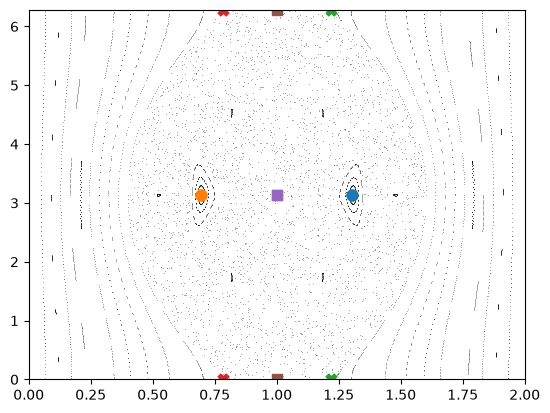

In [5]:
fig, ax = pplot.plot(
    s=0.5,
    xlim=[0, 2],
    ylim=[0, 2*np.pi],
    plottype=None
)


fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([xs1, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([xs2, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([1.2, 0.0]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([0.78, 2*np.pi]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# FP in the chaotic region:
result = fp.find(
    t = 1,
    guess = np.array([1., np.pi]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find(
    t = 1,
    guess = np.array([1., 6.]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

#### Find manifolds

In [5]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([1.22, 0.0]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array(fp1.coords[1]), method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.78, 0.2]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.78, 2*np.pi]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 3]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

In [7]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold1.vector_s = np.real_if_close(manifold1.vector_s)
manifold1.vector_u = np.real_if_close(manifold1.vector_u)

manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold2.vector_s = np.real_if_close(manifold2.vector_s)
manifold2.vector_u = np.real_if_close(manifold2.vector_u)

manifold3 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0]
)
manifold3.vector_s = np.real_if_close(manifold3.vector_s)
manifold3.vector_u = np.real_if_close(manifold3.vector_u)

manifold4 = Manifold(
    map, fp3, fp4,
    dir1=ofp2.coords[0] - fp3.coords[0],
    dir2=ofp2.coords[0] - fp4.coords[0],
    first_stable=False
)
manifold4.vector_s = np.real_if_close(manifold4.vector_s)
manifold4.vector_u = np.real_if_close(manifold4.vector_u)

In [8]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable1, unstable1 = manifold1.compute_adaptive2(tol=3e-3, n_u_extra=-1, n_s_extra=-1)
    
manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable2, unstable2 = manifold2.compute_adaptive2(tol=3e-3, n_u_extra=-2, n_s_extra=-1)

manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable3, unstable3 = manifold3.compute_adaptive2(tol=3e-3, n_u_extra=-1, n_s_extra=-1)

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.3e-3)
stable4, unstable4 = manifold4.compute_adaptive2(tol=3e-3, n_u_extra=-1, n_s_extra=-1)

Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic already recorded, total clinics = 1. skipping...
C:\Users\mirei\OneDrive - epfl.ch\MA3\pyoculus\pyoculus\solvers\manifold.py:294: RuntimeWarning: overflow encountered in exp
  eps_s, eps_u = np.exp(logeps)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\slab_model\fields\slab_bfield_two_pert.py:52: RuntimeWarning: invalid value encountered in sin
  Bx = self.m1*epsilon1*np.sin(alpha1) + self.m2*epsilon2*np.sin(alpha2)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\slab_model\fields\slab_bfield_two_pert.py:53: RuntimeWarning: invalid value encountered in cos
  By = self.iota_prime*(x-self.x0) + epsilon_prime1*np.cos(alpha1) + epsilon_prime2*np.cos(alpha2)
c:\Users\mirei\OneDrive - epfl.ch\MA3\SdS\local\.venv\Lib\site-packages\scipy\integrate\_ode.py:420: UserWarning: dopri5: step size becomes too small
  self._y, self.t = mth(self.f, self.jac or (lambda: None),
Failed to refine clinic at eps_s=3.971183207

In [14]:
stable_unwrapped1 = stable1.copy()
unstable_unwrapped1 = unstable1.copy()
stable_unwrapped1[:, 1] = np.unwrap(stable1[:, 1], period=2*np.pi)
unstable_unwrapped1[:, 1] = np.unwrap(unstable1[:, 1], period=2*np.pi)

stable_unwrapped2 = stable2.copy()
unstable_unwrapped2 = unstable2.copy()
stable_unwrapped2[:, 1] = np.unwrap(stable2[:, 1], period=2*np.pi)
unstable_unwrapped2[:, 1] = np.unwrap(unstable2[:, 1], period=2*np.pi)

stable_unwrapped3 = stable3.copy()
unstable_unwrapped3 = unstable3.copy()
stable_unwrapped3[:, 1] = np.unwrap(stable3[:, 1], period=2*np.pi)
unstable_unwrapped3[:, 1] = np.unwrap(unstable3[:, 1], period=2*np.pi)

stable_unwrapped4 = stable4.copy()
unstable_unwrapped4 = unstable4.copy()
stable_unwrapped4[:, 1] = np.unwrap(stable4[:, 1], period=2*np.pi)
unstable_unwrapped4[:, 1] = np.unwrap(unstable4[:, 1], period=2*np.pi)

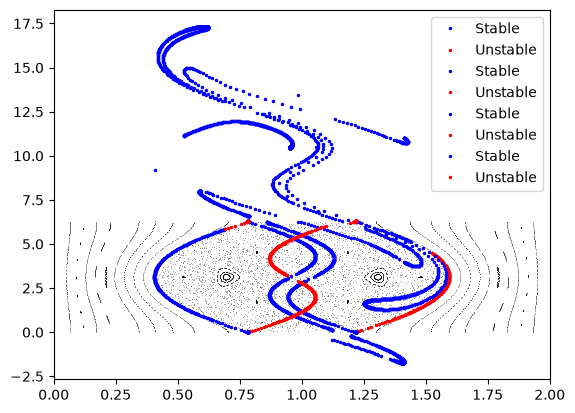

In [15]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], plottype=None)

ax.plot(stable_unwrapped1[:, 0], stable_unwrapped1[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped1[:, 0], unstable_unwrapped1[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped2[:, 0], stable_unwrapped2[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped2[:, 0], unstable_unwrapped2[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped4[:, 0], stable_unwrapped4[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped4[:, 0], unstable_unwrapped4[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.plot(stable_unwrapped3[:, 0], stable_unwrapped3[:, 1], color="blue", label="Stable", marker=".", markersize=3, linestyle="")
ax.plot(unstable_unwrapped3[:, 0], unstable_unwrapped3[:, 1], color="red", label="Unstable", marker=".", markersize=3, linestyle="")

ax.legend()
plt.show()

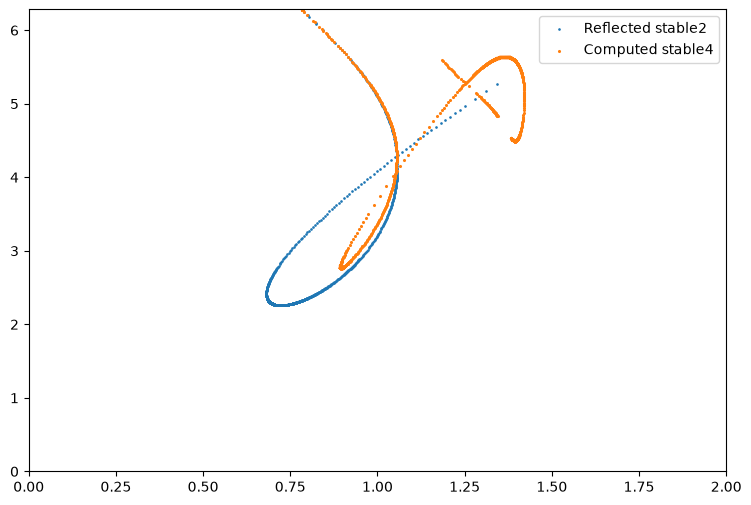

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def reflect_manifold(points, x0=1.0):
    points = np.asarray(np.real_if_close(points))

    reflected = points.copy()
    reflected[:, 0] = 2*x0 - points[:, 0]
    reflected[:, 1] = (-points[:, 1]) % (2*np.pi)

    return reflected

stable2_reflected = reflect_manifold(
    manifold2.stable,
    x0=field.x0
)

plt.figure(figsize=(9, 6))

plt.scatter(
    stable2_reflected[:, 0],
    stable2_reflected[:, 1],
    s=0.8,
    label="Reflected stable2"
)

plt.scatter(
    np.real(manifold4.stable[:, 0]),
    np.real(manifold4.stable[:, 1]),
    s=1.5,
    label="Computed stable4"
)

plt.xlim(0, 2)
plt.ylim(0, 2*np.pi)
plt.legend()
plt.show()

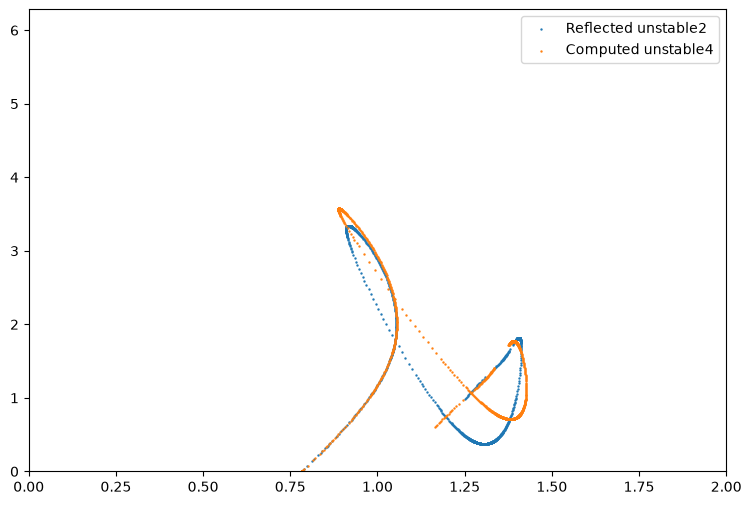

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def reflect_manifold(points, x0=1.0):
    points = np.asarray(np.real_if_close(points))

    reflected = points.copy()
    reflected[:, 0] = 2*x0 - points[:, 0]
    reflected[:, 1] = (-points[:, 1]) % (2*np.pi)

    return reflected

unstable2_reflected = reflect_manifold(
    manifold2.unstable,
    x0=field.x0
)

plt.figure(figsize=(9, 6))

plt.scatter(
    unstable2_reflected[:, 0],
    unstable2_reflected[:, 1],
    s=0.5,
    label="Reflected unstable2"
)

plt.scatter(
    np.real(manifold4.unstable[:, 0]),
    np.real(manifold4.unstable[:, 1]),
    s=0.5,
    label="Computed unstable4"
)

plt.xlim(0, 2)
plt.ylim(0, 2*np.pi)
plt.legend()
plt.show()

In [27]:
manifold2.compute_adaptive(
    tol=5e-3,
    n_s_extra=0,
    n_u_extra=0
)

manifold4.compute_adaptive(
    tol=5e-3,
    n_s_extra=0,
    n_u_extra=0
)

Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.005; using the 2000 points found so far.
Adaptive manifold refinement hit max_iter=50/max_points=2000 without converging to tol=0.0

(array([[0.78300072, 6.2831853 ],
        [0.78300072, 6.2831853 ],
        [0.78300072, 6.28318529],
        ...,
        [1.34994531, 0.94134905],
        [1.35013366, 0.94200971],
        [1.35032209, 0.94267175]], shape=(4029, 2)),
 array([[7.83000718e-01, 1.43937989e-10],
        [7.83000718e-01, 2.24003913e-10],
        [7.83000718e-01, 4.12994251e-10],
        ...,
        [1.43402470e+00, 5.01947711e+00],
        [1.43439189e+00, 5.01746644e+00],
        [1.43475958e+00, 5.01544920e+00]], shape=(4036, 2)))

In [28]:
for name, mf in [("Manifold 2", manifold2),
                 ("Manifold 4", manifold4)]:

    for branch in ["stable", "unstable"]:
        pts = np.asarray(getattr(mf, branch))
        pts = np.real_if_close(pts)

        dx = np.diff(pts[:, 0])
        dy = np.diff(pts[:, 1])

        # Account for periodicity in y
        dy = (dy + np.pi) % (2*np.pi) - np.pi

        length = np.sum(np.hypot(dx, dy))

        print(f"{name}, {branch}:")
        print(f"  Points: {len(pts)}")
        print(f"  Approximate length: {length:.6f}")

Manifold 2, stable:
  Points: 3081
  Approximate length: 82.602801
Manifold 2, unstable:
  Points: 6028
  Approximate length: 210.907345
Manifold 4, stable:
  Points: 4029
  Approximate length: 66.319249
Manifold 4, unstable:
  Points: 4036
  Approximate length: 66.688341


(<Figure size 640x480 with 1 Axes>, <Axes: >)

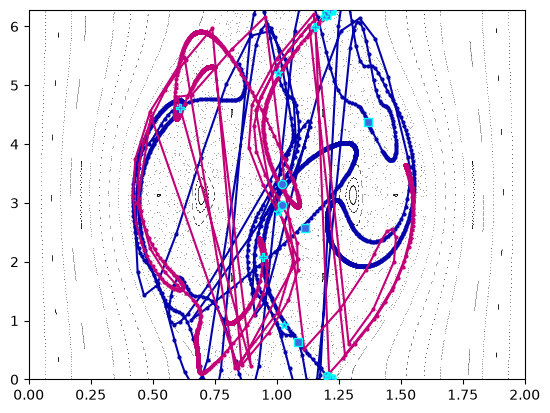

In [66]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

# manifold1.plot("both", ax=ax)
# manifold1.plot_clinics(ax=ax)
manifold2.plot("both", ax=ax)
manifold2.plot_clinics(ax=ax)
# manifold3.plot("both", ax=ax)
# manifold3.plot_clinics(ax=ax)
# manifold4.plot("both", ax=ax)
# manifold4.plot_clinics(ax=ax)
# ax.legend(loc="upper left")

In [6]:

import numpy as np

def numerical_jacobian(map_obj, x, t=2, h=1e-6):
    """Central finite-difference Jacobian of map.f(t, x)."""
    x = np.asarray(x, dtype=float)
    J = np.zeros((2, 2))

    for j in range(2):
        dx = np.zeros(2)
        dx[j] = h

        f_plus = np.asarray(map_obj.f(t, x + dx), dtype=float)
        f_minus = np.asarray(map_obj.f(t, x - dx), dtype=float)

        diff = f_plus - f_minus

        # Account for the periodic angular coordinate
        diff[1] = (diff[1] + np.pi) % (2*np.pi) - np.pi

        J[:, j] = diff / (2*h)

    return J


def eigen_data(J):
    """Return stable/unstable eigenvalues and normalized eigenvectors."""
    values, vectors = np.linalg.eig(J)

    # Sort by increasing absolute eigenvalue
    order = np.argsort(np.abs(values))
    values = values[order]
    vectors = vectors[:, order]

    vectors /= np.linalg.norm(vectors, axis=0)

    return values, vectors


def angle_between(v1, v2):
    """Unsigned angle between two eigenvector directions, in degrees."""
    cos_angle = np.abs(np.vdot(v1, v2))
    cos_angle /= np.linalg.norm(v1) * np.linalg.norm(v2)
    return np.degrees(np.arccos(np.clip(cos_angle, 0, 1)))


def compare_jacobians(map_obj, fp, t=2, h=1e-6):

    x = np.asarray(fp.coords[0], dtype=float)

    J_num = numerical_jacobian(map_obj, x, t=t, h=h)
    J_df = np.asarray(map_obj.df(t, x), dtype=float)
    J_df_T = J_df.T

    matrices = {
        "Numerical": J_num,
        "PyOculus": J_df,
        "PyOculus transposed": J_df_T
    }

    print("Fixed point:", x)
    print("Map iterations:", t)

    print("\n========== JACOBIAN MATRICES ==========")

    for name, J in matrices.items():
        print(f"\n{name}:")
        print(J)
        print("Determinant:", np.linalg.det(J))

    print("\n========== RELATIVE ERRORS ==========")

    for name, J in matrices.items():
        if name == "Numerical":
            continue

        error = np.linalg.norm(J - J_num) / np.linalg.norm(J_num)
        print(f"{name}: {error:.6e}")

    print("\n========== EIGENVALUES ==========")

    eig = {}

    for name, J in matrices.items():
        values, vectors = eigen_data(J)
        eig[name] = (values, vectors)

        print(f"\n{name}:")
        print("Stable eigenvalue:  ", values[0])
        print("Unstable eigenvalue:", values[1])
        print("Stable eigenvector:  ", vectors[:, 0])
        print("Unstable eigenvector:", vectors[:, 1])

    print("\n========== EIGENVECTOR COMPARISON ==========")

    v_num = eig["Numerical"][1]

    for name in ["PyOculus", "PyOculus transposed"]:
        v = eig[name][1]

        angle_s = angle_between(v_num[:, 0], v[:, 0])
        angle_u = angle_between(v_num[:, 1], v[:, 1])

        print(f"\n{name}:")
        print(f"Stable direction error:   {angle_s:.6f} degrees")
        print(f"Unstable direction error: {angle_u:.6f} degrees")

    return matrices, eig


# CHANGE THESE TO YOUR GOOD CONFIGURATION
matrices_good, eig_good = compare_jacobians(
    map_obj=map,
    fp=fp1,
    t=2
)


Fixed point: [1.21699928 6.28318531]
Map iterations: 2

========== JACOBIAN MATRICES ==========

Numerical:
[[2019.96149724  433.91809932]
 [9403.41516398 2019.9796309 ]]
Determinant: -30.955452372474998

PyOculus:
[[ 83340.55576718  21159.40059399]
 [328253.54086832  83340.55496382]]
Determinant: 0.9999998796244683

PyOculus transposed:
[[ 83340.55576718 328253.54086832]
 [ 21159.40059399  83340.55496382]]
Determinant: 0.9999996887126454

========== RELATIVE ERRORS ==========
PyOculus: 3.452049e+01
PyOculus transposed: 3.533541e+01

========== EIGENVALUES ==========

Numerical:
Stable eigenvalue:   (-0.0076623378108706675+0j)
Unstable eigenvalue: (4039.9487904804655+0j)
Stable eigenvector:   [-0.21002309+0.j  0.97769643+0.j]
Unstable eigenvector: [-0.21002129+0.j -0.97769681+0.j]

PyOculus:
Stable eigenvalue:   (5.999492714181542e-06+0j)
Unstable eigenvalue: (166681.11072500137+0j)
Stable eigenvector:   [-0.24608332+0.j  0.96924868+0.j]
Unstable eigenvector: [0.24608333+0.j 0.96924868

In [7]:
def jacobian_convergence(map_obj, fp, t=2):
    x = np.asarray(fp.coords[0], dtype=float)
    J_df = np.asarray(map_obj.df(t, x), dtype=float)

    print(f"{'h':>12} {'det(J_num)':>15} {'relative error':>18}")

    for h in [1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]:
        J_num = numerical_jacobian(map_obj, x, t=t, h=h)

        det = np.linalg.det(J_num)
        err = np.linalg.norm(J_df - J_num) / np.linalg.norm(J_num)

        print(f"{h:12.1e} {det:15.6f} {err:18.6e}")

jacobian_convergence(map_obj=map, fp=fp1, t=1)



           h      det(J_num)     relative error
     1.0e-05        0.999804       4.532541e+00
     1.0e-06        0.999998       4.532541e+00
     1.0e-07        1.000001       4.532541e+00
     1.0e-08        1.000007       4.532541e+00
     1.0e-09        1.000011       4.532541e+00
     1.0e-10        1.000017       4.532524e+00


In [8]:
x = np.asarray(fp1.coords[0], dtype=float)

J_num = numerical_jacobian(map, x, t=2, h=1e-7)
J_old = map.df(2, x)
J_new = map.df_corrected(2, x)

print("Numerical Jacobian:")
print(J_num)

print("\nOriginal PyOculus Jacobian:")
print(J_old)

print("\nCorrected Jacobian:")
print(J_new)

print("\nRelative error (original):",
      np.linalg.norm(J_old - J_num) / np.linalg.norm(J_num))

print("Relative error (corrected):",
      np.linalg.norm(J_new - J_num) / np.linalg.norm(J_num))

Numerical Jacobian:
[[2019.97954281  433.91828774]
 [9403.42273571 2019.97975049]]

Original PyOculus Jacobian:
[[ 83340.55576718  21159.40059399]
 [328253.54086832  83340.55496382]]

Corrected Jacobian:
[[2019.97966529  433.91826824]
 [9403.42262145 2019.97967088]]

Relative error (original): 34.52045402073353
Relative error (corrected): 1.895642603546767e-08
